# 04 – Backtest: decision, auction bids and settlement

This notebook only **loads the outputs** of `python -m src.backtest.run_backtest` and shows them. Strategy 4 (`ml_battery`) is our product. Check the `forecast_source` column: `standin` means the ML prediction files did not exist yet.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
summary = pd.read_csv('reports/backtest_summary.csv')
print('forecast source:', summary['forecast_source'].unique())

forecast source: <ArrowStringArray>
['standin']
Length: 1, dtype: str


## Summary per split and strategy (CHF)

In [2]:
cols = ['split','label','total_cost_chf','saving_vs_baseline_chf','saving_ci_low_chf','saving_ci_high_chf','pct_perfect_captured',
        'battery_value_chf','pct_battery_value_captured','imbalance_penalty_chf','wear_cost_chf','cycles','days_battery_idle','share_charge_cleared']
summary[summary.split=='test'][cols].round(1)

,split,label,total_cost_chf,saving_vs_baseline_chf,saving_ci_low_chf,saving_ci_high_chf,pct_perfect_captured,battery_value_chf,pct_battery_value_captured,imbalance_penalty_chf,wear_cost_chf,cycles,days_battery_idle,share_charge_cleared
7,test,"1 Baseline: naive, no battery",45685820.2,0.0,0.0,0.0,0.0,NaN,NaN,314815.7,0.0,0.0,31,NaN
8,test,"2 ML demand, no battery",45751522.6,-65702.4,-123490.2,-10536.5,-19.2,NaN,NaN,380518.1,0.0,0.0,31,NaN
9,test,3 Naive + battery,45679941.0,5879.2,-12925.3,26004.6,1.7,5879.2,21.0,323838.9,1333.2,8.9,17,0.3
10,test,4 ML + battery (product),45737909.5,-52089.3,-119985.0,9253.1,-15.2,13613.1,48.7,388857.6,2112.1,14.2,6,0.4
11,test,5 Perfect foresight + battery,45343066.6,342753.6,269422.8,428066.4,100.0,27937.9,100.0,0.0,3319.4,22.3,3,1.0
12,test,"6 Perfect foresight, hourly plan",45316378.8,369441.4,296973.5,455346.2,107.8,54625.7,195.5,0.0,4384.4,29.5,0,1.0
13,test,"7 Perfect demand, no battery",45371004.5,314815.7,240756.6,403725.3,91.8,NaN,NaN,0.0,0.0,0.0,31,NaN


In [3]:
summary[summary.split=='val'][cols].round(1)

,split,label,total_cost_chf,saving_vs_baseline_chf,saving_ci_low_chf,saving_ci_high_chf,pct_perfect_captured,battery_value_chf,pct_battery_value_captured,imbalance_penalty_chf,wear_cost_chf,cycles,days_battery_idle,share_charge_cleared
0,val,"1 Baseline: naive, no battery",32883845.1,0.0,0.0,0.0,0.0,NaN,NaN,209071.2,0.0,0.0,30,NaN
1,val,"2 ML demand, no battery",32917392.5,-33547.4,-84009.3,16737.2,-12.1,NaN,NaN,242618.6,0.0,0.0,30,NaN
2,val,3 Naive + battery,32820441.3,63403.8,47112.1,83151.5,22.8,63403.8,92.7,206535.0,3297.5,21.8,0,0.8
3,val,4 ML + battery (product),32851575.3,32269.8,-27190.8,90573.6,11.6,65817.2,96.2,238818.8,3420.2,22.7,1,0.8
4,val,5 Perfect foresight + battery,32606355.9,277489.1,239583.1,318945.7,100.0,68418.0,100.0,0.0,4152.3,27.5,0,1.0
5,val,"6 Perfect foresight, hourly plan",32576819.0,307026.0,268627.8,349404.4,110.6,97954.8,143.2,0.0,4318.6,28.6,0,1.0
6,val,"7 Perfect demand, no battery",32674773.9,209071.2,166527.1,256576.4,75.3,NaN,NaN,0.0,0.0,0.0,30,NaN


## Where does the saving come from?
`total = demand-forecast part (1−2) + battery part (2−4)`

In [4]:
pd.read_csv('reports/backtest_decomposition.csv').set_index('split').T.round(1)

split,val,test
total_saving_chf,32269.8,-52089.3
demand_forecast_part_chf,-33547.4,-65702.4
battery_part_chf,65817.2,13613.1
perfect_total_saving_chf,277489.1,342753.6
perfect_battery_value_chf,68418.0,27937.9
forecast_error_cost_ml_chf,242618.6,380518.1
forecast_error_cost_naive_chf,209071.2,314815.7
pct_perfect_captured_total,11.6,-15.2
pct_perfect_battery_value_captured,96.2,48.7
block_simplification_cost_chf,29536.9,26687.8


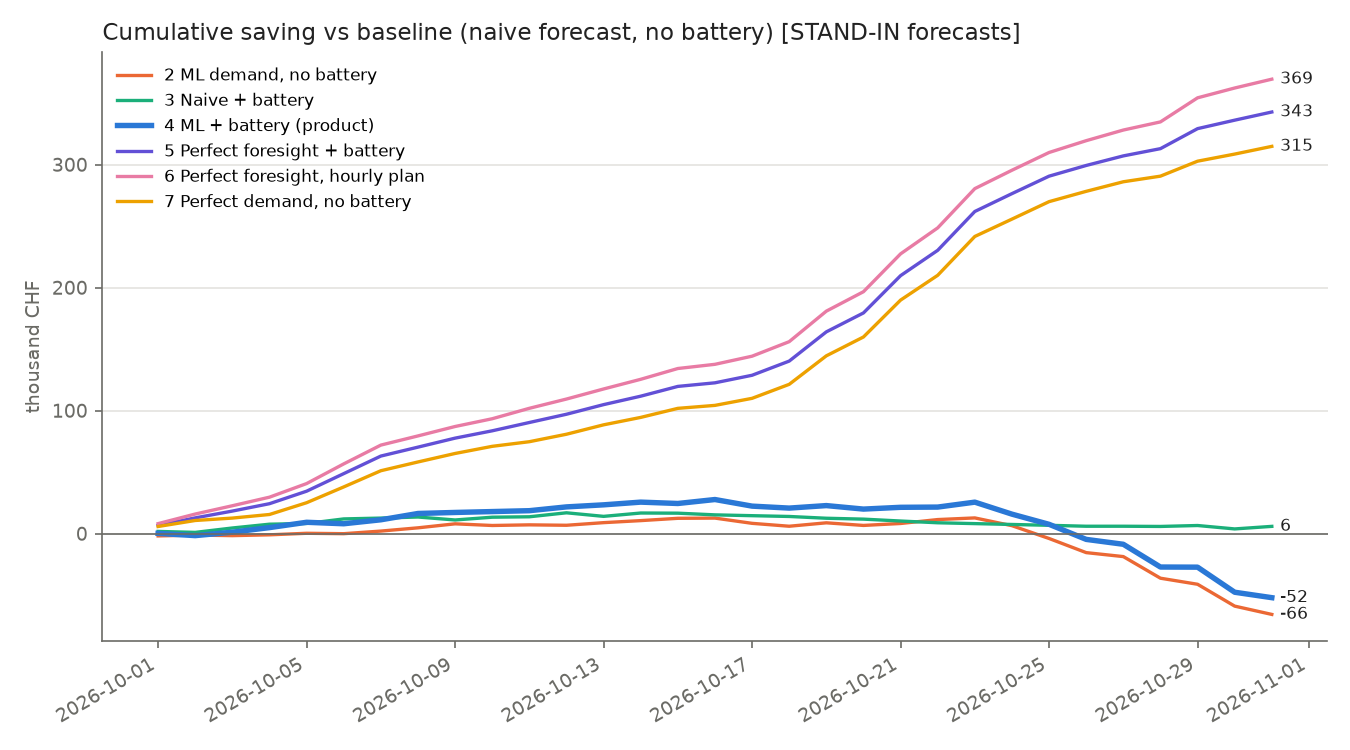

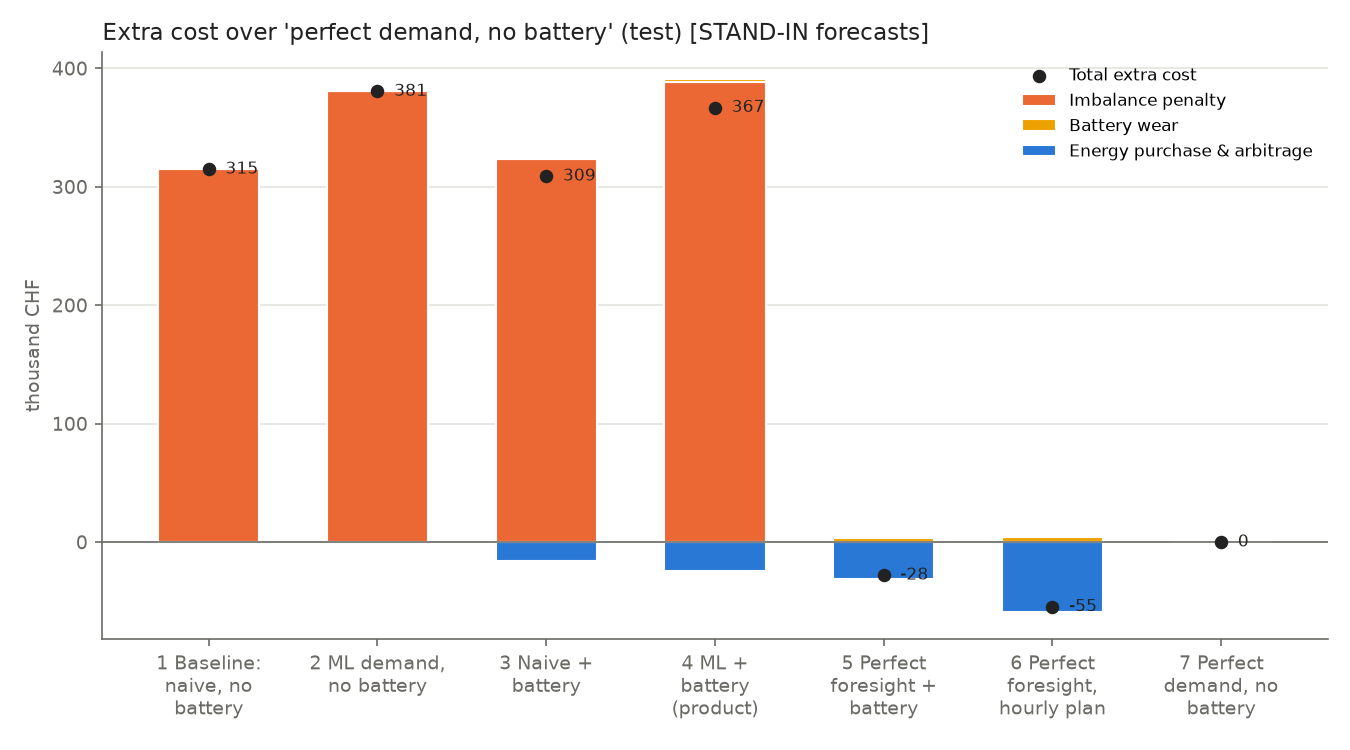

In [5]:
display(Image('reports/figures/backtest_cumulative_savings_test.png'))
display(Image('reports/figures/backtest_cost_breakdown.png'))

## Checks: days where the order perfect ≤ product ≤ baseline does not hold

In [6]:
exc = pd.read_csv('reports/backtest_exceptions.csv')
exc.groupby(['split','check','reason']).size().rename('days').reset_index()

,split,check,reason,days
0,test,ml_battery > baseline,demand forecast: the ML demand forecast was fu...,11
1,test,ml_battery > baseline,limit bid not (fully) cleared: less energy sto...,3
2,test,perfect_foresight > ml_battery,charge-level carry-over: ml_battery took more ...,1
3,val,ml_battery > baseline,demand forecast: the ML demand forecast was fu...,11


## Decision tuning (validation month only)

In [7]:
pd.read_csv('reports/decision_tuning.csv').sort_values('objective_chf').head(6)

,forecast_source,charge_limit_factor,min_spread_eur_mwh,cost_val_chf,cycles_val,objective_chf,is_default,vs_default_chf,chosen
0,standin,0.8,0.0,3.285158e+07,22.662643,3.285158e+07,False,-3070.927444,True
1,standin,0.8,5.0,3.285212e+07,22.662643,3.285212e+07,False,-2525.576503,False
2,standin,0.8,10.0,3.285212e+07,22.662643,3.285212e+07,False,-2525.576503,False
5,standin,0.9,5.0,3.285464e+07,25.902937,3.285464e+07,False,-7.297314,False
6,standin,0.9,10.0,3.285464e+07,25.902937,3.285464e+07,False,-7.297314,False
4,standin,0.9,0.0,3.285465e+07,26.119302,3.285465e+07,True,0.000000,False


## Sensitivities (test month, for information)

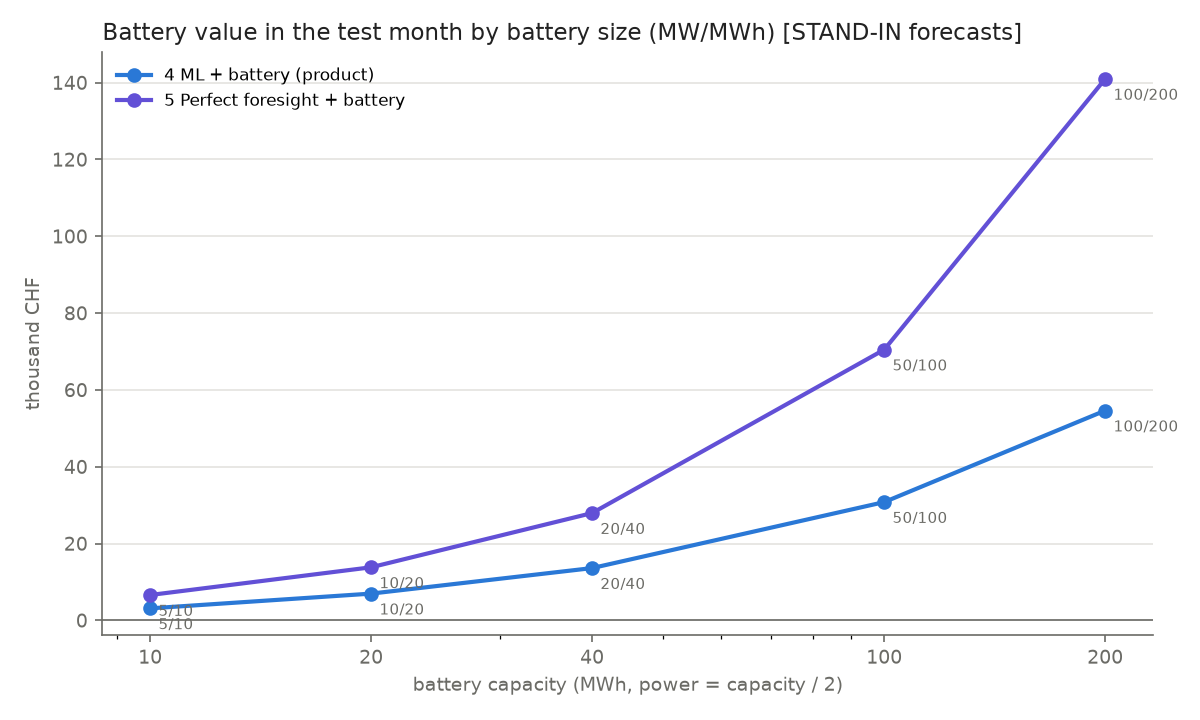

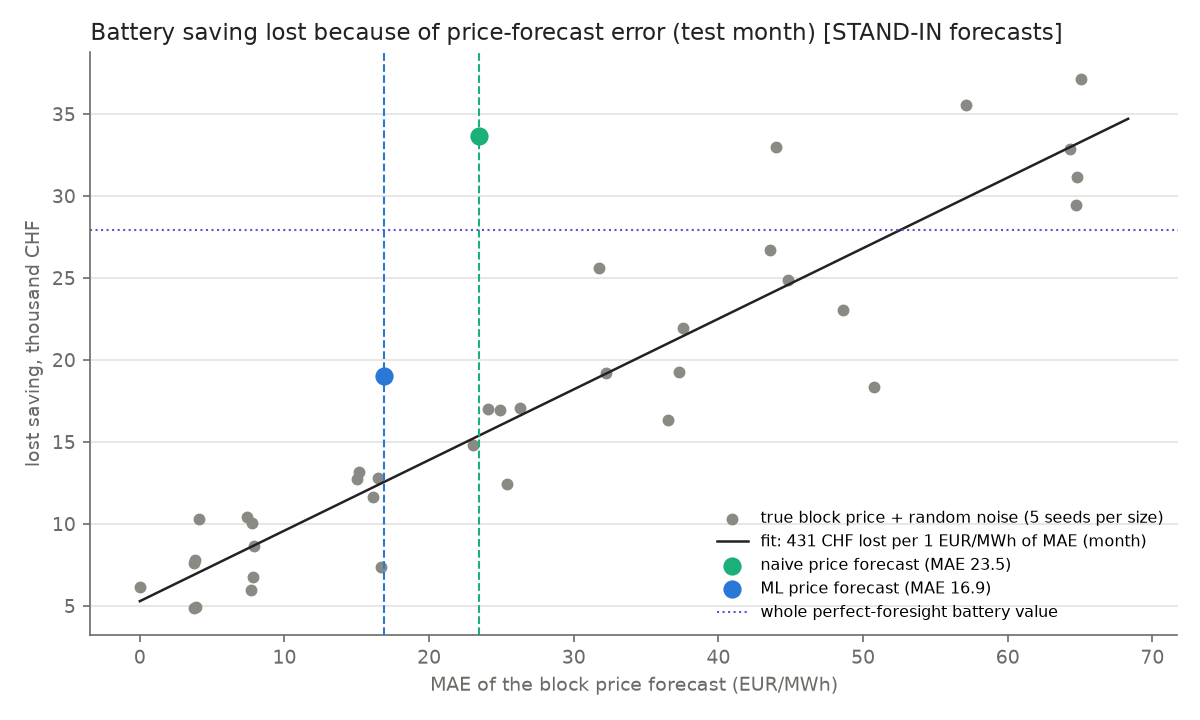

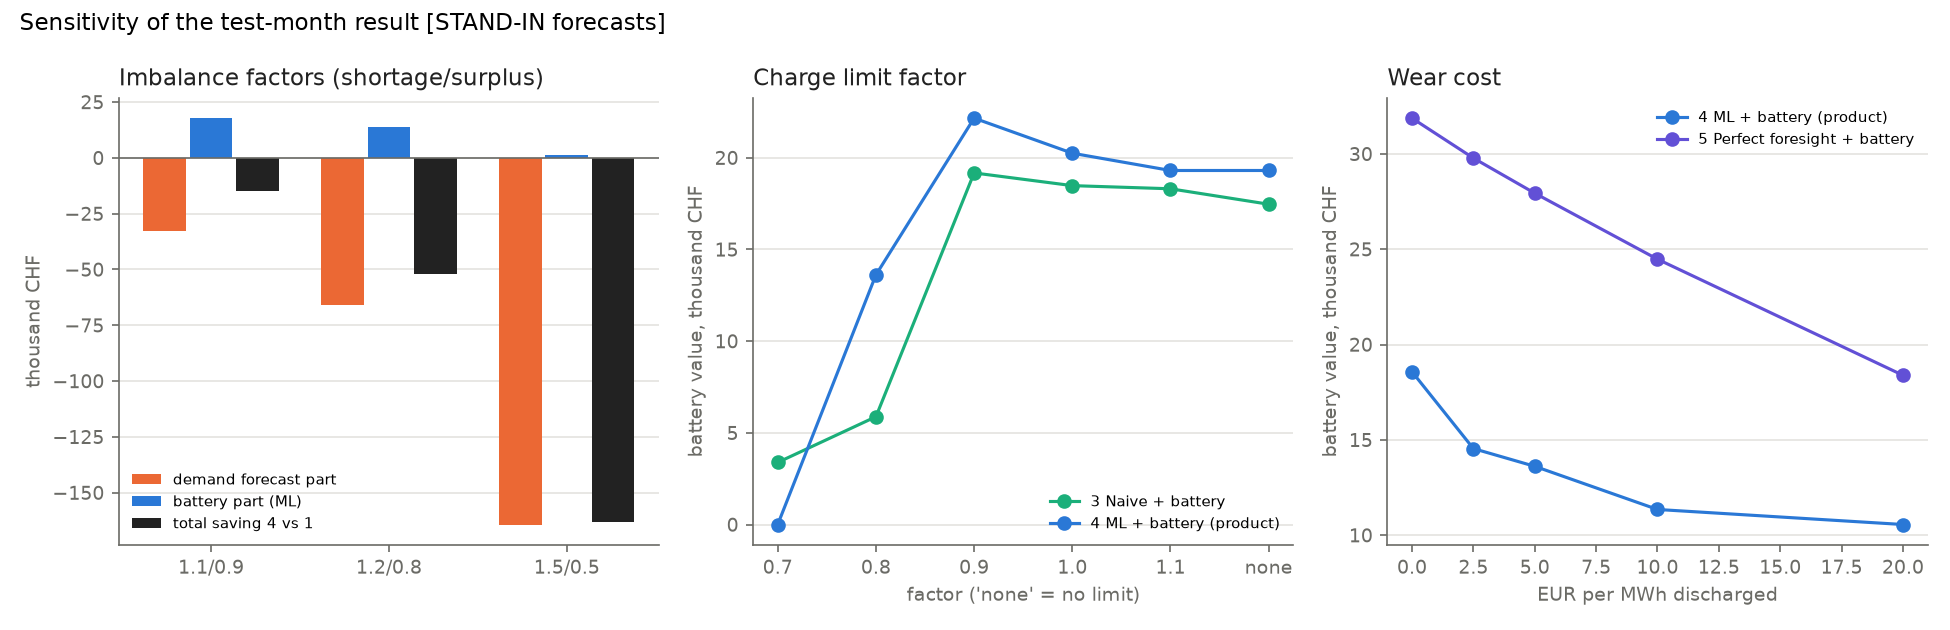

In [8]:
display(Image('reports/figures/backtest_battery_size_sensitivity.png'))
display(Image('reports/figures/backtest_price_error_sensitivity.png'))
display(Image('reports/figures/backtest_decision_sensitivity.png'))

## One day in detail: plan, hourly bids and settlement

In [9]:
from src.backtest.run_backtest import plan_day, tuned_decision
from src.decision.bids import bids_table
r = plan_day('2026-10-14', 'ml_battery', decision=tuned_decision())
display(r['plan'].round(2))
display(bids_table(r['bids']).head(8))
{k: (round(v, 1) if isinstance(v, float) else v) for k, v in r['summary'].items()}

,period,block,hours,demand_mwh,price_eur_mwh,buy_mwh,charge_mwh,discharge_mwh,sell_mwh,soc_mwh,option,charge_limit_eur_mwh
0,0,0,4.0,862.04,189.84,878.90,16.87,0.00,0.0,36.0,buy_and_store,177.44
1,1,1,4.0,999.03,211.70,999.03,0.00,0.00,0.0,36.0,buy,NaN
2,2,2,4.0,1373.50,217.98,1373.50,0.00,0.00,0.0,36.0,buy,NaN
3,3,3,4.0,1400.79,192.71,1400.79,0.00,0.00,0.0,36.0,buy,NaN
4,4,4,4.0,1388.95,228.05,1373.77,0.00,15.18,0.0,20.0,use_storage_and_buy,NaN
5,5,5,4.0,1126.86,214.16,1126.86,0.00,0.00,0.0,20.0,buy,NaN


,Date,Hour (local),Block,Demand bid MWh (price-independent),Charge bid MWh,Charge limit EUR/MWh,Total bid MWh
0,2026-10-14,00:00 (UTC+02),00-04,232.054,4.216,177.44,236.271
1,2026-10-14,01:00 (UTC+02),00-04,212.936,4.216,177.44,217.152
2,2026-10-14,02:00 (UTC+02),00-04,213.149,4.216,177.44,217.366
3,2026-10-14,03:00 (UTC+02),00-04,203.899,4.216,177.44,208.115
4,2026-10-14,04:00 (UTC+02),04-08,202.958,0.000,-,202.958
5,2026-10-14,05:00 (UTC+02),04-08,223.033,0.000,-,223.033
6,2026-10-14,06:00 (UTC+02),04-08,265.285,0.000,-,265.285
7,2026-10-14,07:00 (UTC+02),04-08,307.751,0.000,-,307.751


{'delivery_date': datetime.date(2026, 10, 14),
 'strategy': 'ml_battery',
 'forecast_demand_mwh': 7151.2,
 'actual_demand_mwh': 7050.9,
 'demand_bid_mwh': 7136.0,
 'charge_bid_mwh': 16.9,
 'charge_cleared_mwh': 0.0,
 'share_charge_cleared': 0.0,
 'energy_bought_mwh': 7136.0,
 'charged_mwh': 0.0,
 'planned_discharge_mwh': 15.2,
 'discharged_mwh': 15.2,
 'discharge_not_delivered_mwh': 0.0,
 'cycles': 0.5,
 'battery_idle': False,
 'plan_has_discharge': True,
 'shortage_mwh': 6.9,
 'surplus_mwh': 107.1,
 'soc_start_mwh': 20.0,
 'soc_end_mwh': np.float64(4.0),
 'soc_target_relaxed': False,
 'da_cost_eur': 1561017.8,
 'imbalance_cost_eur': -15689.7,
 'imbalance_penalty_eur': 4698.3,
 'wear_cost_eur': 75.9,
 'total_cost_eur': 1545404.0,
 'da_cost_chf': 1456429.6,
 'imbalance_cost_chf': -14638.5,
 'imbalance_penalty_chf': 4383.5,
 'wear_cost_chf': 70.8,
 'total_cost_chf': 1441861.9}